In [94]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


Project Goal: Analyze a technology store's sales data, uncover useful business insights, visualize performance, and present recommendations as if a store manager had asked me to investigate the business.

# Investigation

In [95]:
df = pd.read_csv("tech_store_sales_practice.csv")
print(df.describe())
print(df.head())
print(df.shape)


       Units_Sold  Unit_Price_USD   Revenue_USD  Ad_Spend_USD  \
count  150.000000      150.000000    150.000000    150.000000   
mean     7.400000      274.266667   2020.066667    267.407800   
std      4.091241      290.355826   2437.901919    133.784185   
min      1.000000       50.000000     50.000000     50.350000   
25%      4.000000       90.000000    500.000000    152.445000   
50%      7.500000      120.000000   1200.000000    267.105000   
75%     11.000000      300.000000   2650.000000    394.807500   
max     14.000000     1200.000000  15600.000000    494.100000   

       Customer_Rating  Returned_Units  
count       150.000000      150.000000  
mean          4.259800        0.120000  
std           0.428609        0.432256  
min           3.500000        0.000000  
25%           3.880000        0.000000  
50%           4.295000        0.000000  
75%           4.610000        0.000000  
max           4.990000        2.000000  
         Date     Category                   

# Data Quality

Checking whether there is any missing or duplicated rows and investigate whether Date is a datetime column.

In [96]:
df.isnull().sum()
df.isnull().values.any()

df.columns[df.columns.duplicated()].to_list()
df["Date"] = pd.to_datetime(df["Date"])


# Validating the Data

Checking for impossible or suspicious values in Units_Sold, Unit_Price_USD, Revenue_USD, Ad_Spend_USD, Customer_Rating, and Returned_Units.

In [97]:
print((df["Returned_Units"] > df["Units_Sold"]).sum())
print((df["Revenue_USD"] != df["Units_Sold"] * df["Unit_Price_USD"]).sum())

0
0


# EDA (Exploratory Data Analysis)

Goal: Calculate total revenue, total units sold, total advertising spend, total returned units, and average customer rating.

In [98]:
calculate = df.groupby("Product").agg({
    "Revenue_USD": "sum",
    "Units_Sold": "sum",
    "Ad_Spend_USD":"sum",
    "Returned_Units": "sum",
    "Customer_Rating": "mean"
})

print(calculate)


                            Revenue_USD  Units_Sold  Ad_Spend_USD  \
Product                                                             
Bluetooth Speaker                  7920          88       3730.20   
Fitness Band                      15800         158       6680.72   
Laptop Pro                        79200          66       2153.61   
Mechanical Keyboard               15600         130       2925.87   
Noise-Canceling Headphones        37750         151       6822.28   
Smart Monitor                     61200         136       4251.50   
Smartwatch Series X               45300         151       4282.34   
Tablet Air                        28800          48       1974.70   
USB-C Dock                         6240          78       3083.35   
Wireless Mouse                     5200         104       4206.60   

                            Returned_Units  Customer_Rating  
Product                                                      
Bluetooth Speaker                        4     

# Product Summary

In [99]:
total_reveneu = df["Revenue_USD"].sum()
total_units = df["Units_Sold"].sum()
total_ad_Spend = df["Ad_Spend_USD"].sum()
total_returned_Unit = df["Returned_Units"].sum()
customer_rating = df["Customer_Rating"].mean()

print(f"Total Revenue: {total_reveneu}")
print(f"Total Units Sold: {total_units}")
print(f"Total Ad Spend: {total_ad_Spend}")
print(f"Total Returned Unit: {total_returned_Unit}")
print(f"Average Customer Rating: {customer_rating:.2f}")


Total Revenue: 303010
Total Units Sold: 1110
Total Ad Spend: 40111.17
Total Returned Unit: 18
Average Customer Rating: 4.26


# Revenue By Product

Goal: Find the top five products by total revenue

In [100]:
top_product = df.groupby("Product")["Revenue_USD"].sum().reset_index()
top_product = top_product.sort_values(by="Revenue_USD", ascending=False).head(5)
print(top_product)


                      Product  Revenue_USD
2                  Laptop Pro        79200
5               Smart Monitor        61200
6         Smartwatch Series X        45300
4  Noise-Canceling Headphones        37750
7                  Tablet Air        28800


# Revenue By Category

Goal: Compare total revenue across categories.

In [101]:
total_revenue = df.groupby("Category")["Revenue_USD"].sum().reset_index()
print(total_revenue)


      Category  Revenue_USD
0  Accessories        27040
1        Audio        45670
2  Electronics       169200
3    Wearables        61100


# Revenue By Region

Goal: Compare total revenue across regions.

In [102]:
region = df.groupby("Region")["Revenue_USD"].sum().reset_index()
print(region.sort_values(by="Revenue_USD",ascending=False))


  Region  Revenue_USD
2  South        95970
3   West        83960
0   East        66440
1  North        56640


# Average Customer Rating

Goal: Identify which product has the highest average customer rating

In [103]:
rating = df.groupby("Product")["Customer_Rating"].mean()
sorted = rating.sort_values(ascending=False)
print(sorted)

Product
Tablet Air                    4.530000
Laptop Pro                    4.400000
Noise-Canceling Headphones    4.385909
USB-C Dock                    4.375833
Smartwatch Series X           4.291875
Fitness Band                  4.220000
Bluetooth Speaker             4.158333
Wireless Mouse                4.154000
Smart Monitor                 4.152941
Mechanical Keyboard           4.100000
Name: Customer_Rating, dtype: float64


# Data Visualization

Product Performance

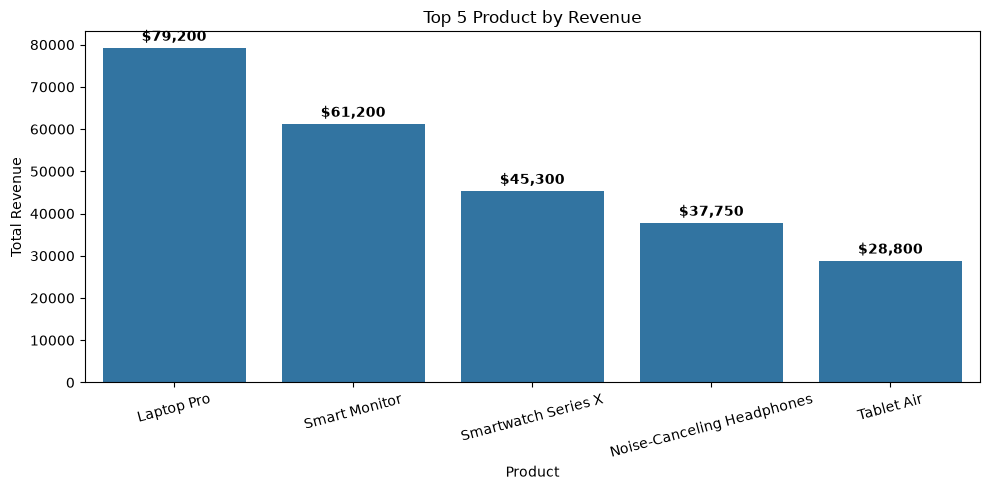

In [104]:
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=top_product,
    x="Product",
    y="Revenue_USD"
)

for p in ax.patches:
    ax.annotate(
        f"${p.get_height():,.0f}",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="center",
        xytext=(0, 8),
        textcoords="offset points",
        fontweight="bold",
    )

plt.title("Top 5 Product by Revenue")
plt.xlabel("Product")
plt.ylabel("Total Revenue")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Category and Regional Revenue


Goal: Compare how categories and regions perform

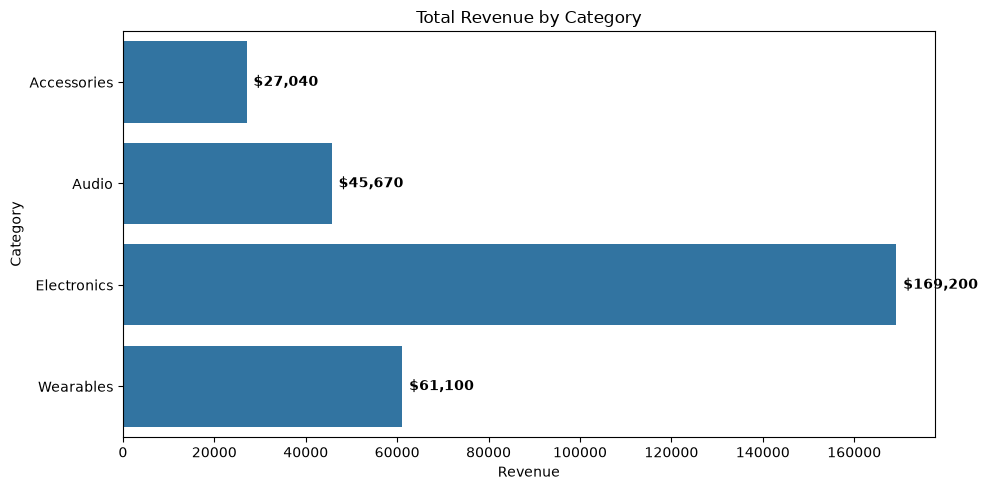

In [105]:
plt.figure(figsize=(10, 5))
ab = sns.barplot(
    data=total_revenue,
    x="Revenue_USD",
    y="Category",
)

for i in ab.patches:
    width = i.get_width()  
    ab.annotate(
        f"${width:,.0f}",  
        (width, i.get_y() + i.get_height() / 2.0),
        ha="left",
        va="center",
        xytext=(5, 0),
        textcoords="offset points",
        fontweight="bold",
    )

plt.title("Total Revenue by Category")
plt.xlabel("Revenue")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

# Revenue by Region

Goal: find which region has the highest revenue

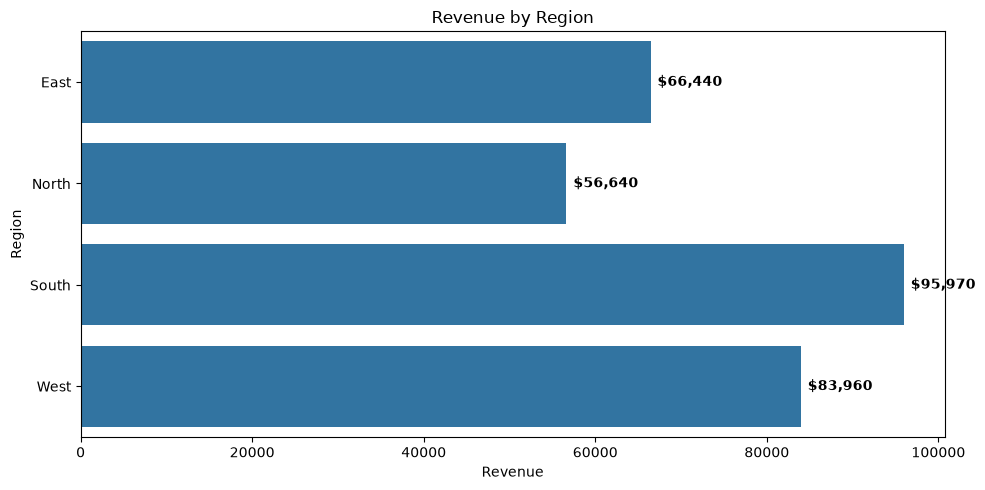

In [106]:
plt.figure(figsize=(10, 5))
ha = sns.barplot(
    data=region,
    x="Revenue_USD",
    y="Region"
)

for i in ha.patches:
    width = i.get_width()  
    ha.annotate(
        f"${width:,.0f}",  
        (width, i.get_y() + i.get_height() / 2.0),
        ha="left",
        va="center",
        xytext=(5, 0),
        textcoords="offset points",
        fontweight="bold",
    )

plt.title("Revenue by Region")
plt.xlabel("Revenue")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

# Monthly Revenue

In [122]:
monthly_revenue = (df.groupby(df["Date"].dt.to_period("M"))["Revenue_USD"].sum().reset_index())
monthly_revenue["Date_Timestamp"] = monthly_revenue["Date"].dt.to_timestamp()
print(monthly_revenue.head(5).sort_values("Revenue_USD", ascending=False))

      Date  Revenue_USD Date_Timestamp
1  2026-02        67000     2026-02-01
4  2026-05        63670     2026-05-01
2  2026-03        62810     2026-03-01
0  2026-01        55270     2026-01-01
3  2026-04        54260     2026-04-01


# Daily Revenue

In [108]:
daily_revenue = df.groupby("Date")["Revenue_USD"].sum()
print(daily_revenue.head(5))

Date
2026-01-01     990
2026-01-02    1250
2026-01-03    1800
2026-01-04    1080
2026-01-05    4200
Name: Revenue_USD, dtype: int64


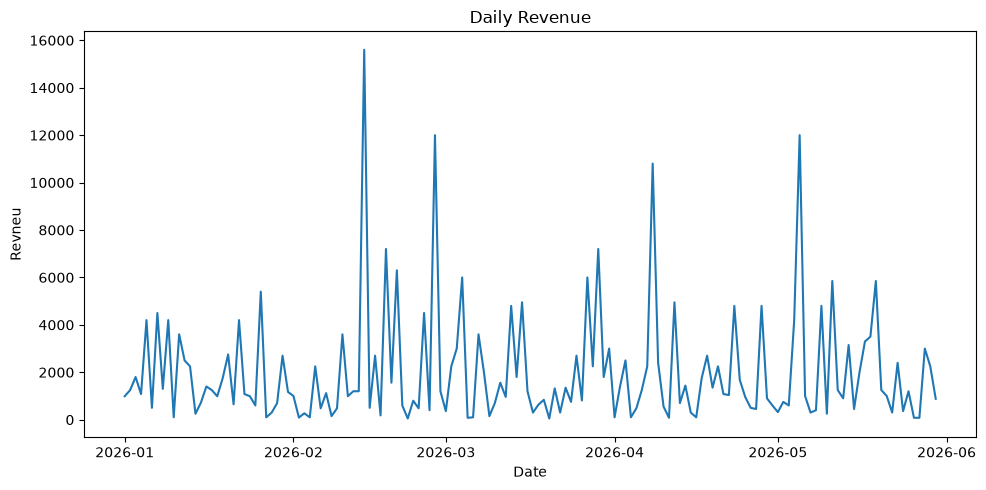

In [109]:
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=df,
    x="Date",
    y="Revenue_USD"
)

plt.title("Daily Revenue")
plt.xlabel("Date")
plt.ylabel("Revneu")
plt.tight_layout()
plt.show()

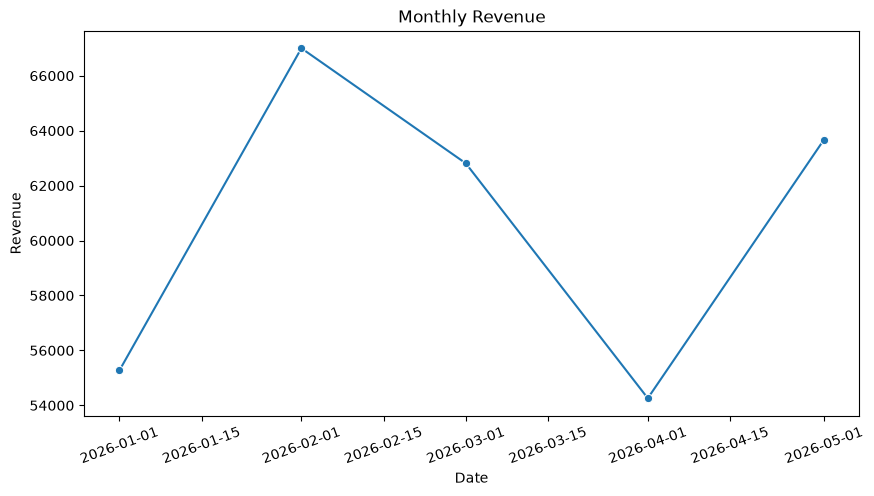

In [121]:
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=monthly_revenue,
    x="Date_Timestamp",
    y="Revenue_USD",
    marker="o"
)

plt.title("Monthly Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.xticks(rotation=20)
plt.show()

# Correlation Heatmap

Goal: Create a correlation heatmap using seaborn

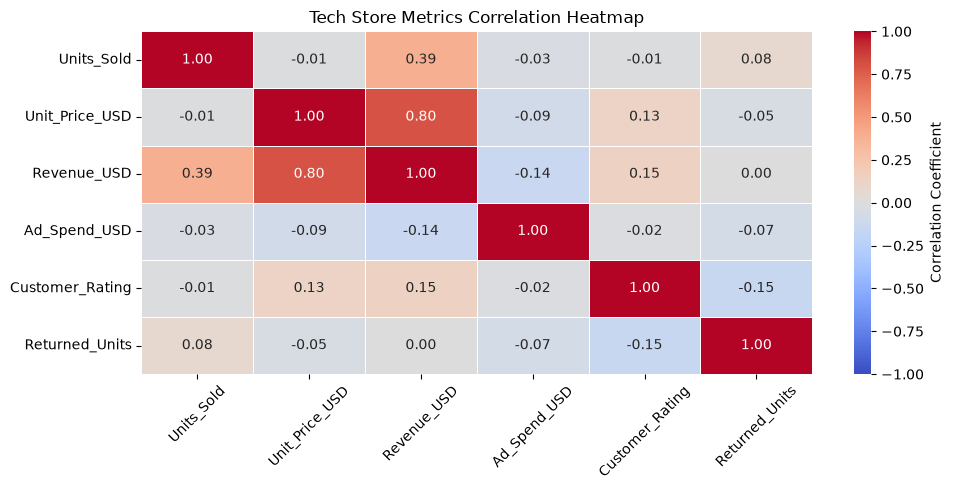

In [125]:
numerical_cols = [
    "Units_Sold",
    "Unit_Price_USD",
    "Revenue_USD",
    "Ad_Spend_USD",
    "Customer_Rating",
    "Returned_Units"
]

corr_matrix = df[numerical_cols].corr()
plt.figure(figsize=(10, 5))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    cbar_kws={"label": "Correlation Coefficient"}
)

plt.title("Tech Store Metrics Correlation Heatmap")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Advertising Spend vs Revenue

Goal: Investigate whether higher advertising spend tends to be associated with higher revenue

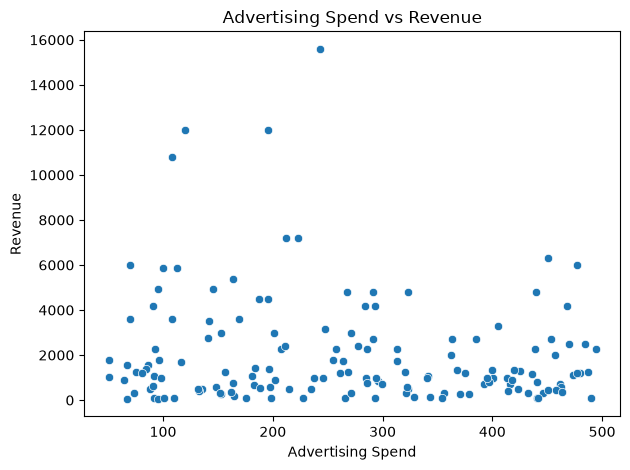

In [126]:
sns.scatterplot(
    data=df,
    x="Ad_Spend_USD",
    y="Revenue_USD"
)


plt.title("Advertising Spend vs Revenue")
plt.xlabel("Advertising Spend")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

# Customer Rating by Product Category

Goal: Create a Seaborn bar plot showing the average customer rating for each category.

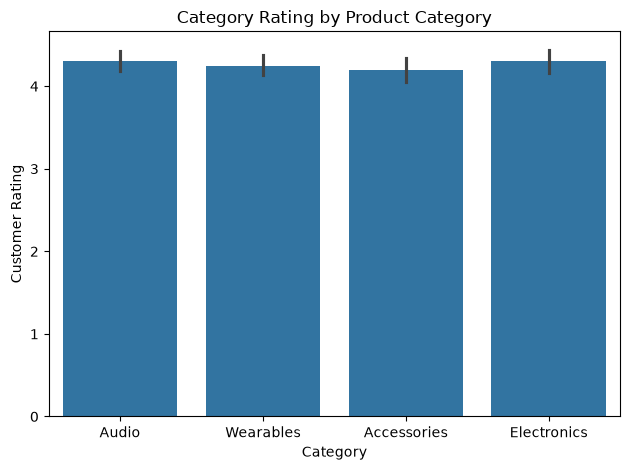

In [127]:
sns.barplot(
    data=df,
    x="Category",
    y="Customer_Rating"
)

plt.title("Category Rating by Product Category")
plt.xlabel("Category")
plt.ylabel("Customer Rating")
plt.tight_layout()
plt.show()

# Business Investigation

Investigation 1

 Feature Engineering

In [132]:
product_return = (df.groupby("Product").agg({
    "Returned_Units": "sum",
    "Units_Sold": "sum"
}))

product_return["Return_Rate"] = (product_return["Returned_Units"] / product_return["Units_Sold"]) * 100
print(product_return.sort_values(
    "Return_Rate",
    ascending=False
).head(5))

                     Returned_Units  Units_Sold  Return_Rate
Product                                                     
Bluetooth Speaker                 4          88     4.545455
Wireless Mouse                    4         104     3.846154
Mechanical Keyboard               3         130     2.307692
Tablet Air                        1          48     2.083333
Laptop Pro                        1          66     1.515152


Investigation 2

Goal: Find which products generate the most revneue but also have high return rates

In [133]:
product_revenue = (df.groupby("Product").agg({
    "Revenue_USD": "sum",
    "Units_Sold": "sum",
    "Returned_Units": "sum"
}))

product_revenue["Return_Rate"] = (product_revenue["Returned_Units"] / product_revenue["Units_Sold"]) * 100
print(product_revenue.sort_values(
    "Revenue_USD",
    ascending=False
).head(5)
)

                            Revenue_USD  Units_Sold  Returned_Units  \
Product                                                               
Laptop Pro                        79200          66               1   
Smart Monitor                     61200         136               2   
Smartwatch Series X               45300         151               0   
Noise-Canceling Headphones        37750         151               1   
Tablet Air                        28800          48               1   

                            Return_Rate  
Product                                  
Laptop Pro                     1.515152  
Smart Monitor                  1.470588  
Smartwatch Series X            0.000000  
Noise-Canceling Headphones     0.662252  
Tablet Air                     2.083333  


Business Recommendation: 
I'd prioritize protecting Laptop Pro's revenue contribution, investigate why Tablet Air has a higher return rate, and assess whether Smartwatch Series X has enough demand and margin to justify increased inventory.

# Advertising Efficiency

Goal: o calculate total Revenue_USD and total Ad_Spend_USD for each product. Then create a new column

In [147]:
advertising_efficiency = (df.groupby("Product").agg({
    "Revenue_USD": "sum",
    "Ad_Spend_USD": "sum",
    "Units_Sold": "sum",
    "Returned_Units": "sum"
}).reset_index())

advertising_efficiency["Return_Rate"] = (advertising_efficiency["Returned_Units"] / advertising_efficiency["Units_Sold"]) * 100

advertising_efficiency["ROAS"] = (advertising_efficiency["Revenue_USD"]
                           / advertising_efficiency["Ad_Spend_USD"]
                           )

print(advertising_efficiency.sort_values(
    by="Return_Rate",
    ascending=False
).head(5))

               Product  Revenue_USD  Ad_Spend_USD  Units_Sold  Returned_Units  \
0    Bluetooth Speaker         7920       3730.20          88               4   
9       Wireless Mouse         5200       4206.60         104               4   
3  Mechanical Keyboard        15600       2925.87         130               3   
7           Tablet Air        28800       1974.70          48               1   
2           Laptop Pro        79200       2153.61          66               1   

   Return_Rate       ROAS  
0     4.545455   2.123211  
9     3.846154   1.236153  
3     2.307692   5.331747  
7     2.083333  14.584494  
2     1.515152  36.775461  
